# Paper figures: main results

Makes the main results figures and table for the paper, from the final training runs on Qwen3-8B (`output/qwen3-8b/`), OLMo-3-7B-Think (`output/olmo3-7b/`) and Seed-Coder-8B-Reasoning (`output/seed-coder-8b/`). Each model has one run per reward (import, usage, target), all with the same recipe and 4 epochs, and every epoch is evaluated.

- **Figure 1:** library use over training, on the training data's held-out test split and on LibReuseBench test.
- **Figure 1 (reward version):** as figure 1, with each run's own reward (training batches and held-out split) on the left.
- **Table 1:** each run's final checkpoint against its base model, on LibReuseBench test and control, HumanEval+ and LiveCodeBench.
- **Figure 2:** the plain prompt against the suffix *"Use an external library when appropriate."*, for each base model and final checkpoint.

**Every run is reported at its final epoch (epoch 4).** This was fixed before training, so no checkpoint is chosen by looking at test results.

**How the values are computed:**

- every metric is averaged within each task's 5 samples, then over tasks;
- error bars are ±1 standard error over tasks;
- differences against the base model have a 95% paired-bootstrap interval over tasks (10,000 resamples);
- **library use** is the share of responses that import and use a third-party library, and **high-value reuse** is library use on the test tasks in the high reuse tier (a library saves 15 or more lines);
- **lines saved**: an answer that uses a library saves however many logical lines shorter it is than the same model's base version's average hand-written answer (plain prompt) to the task, and an answer without a library saves 0. Tasks the base model never answered by hand are left out;
- **tokens**: the tokens generated per response, reasoning included.

The figures (PNG) and the LaTeX table are saved in `output/figures/`.

In [1]:
"""Make the main results figures and table for the paper."""

import json
import math
import os
from functools import cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from llm_cgr import load_jsonl
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

from src.utils.paths import baseline_dir, training_run_dir


# run from the repo root (the folder holding .git), so the relative paths src uses
# (config/, output/) resolve - its results are in output/
REPO_ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / ".git").exists()
)
os.chdir(REPO_ROOT)

# the paper's models, by their key in config/models.yaml, with the name the paper uses
MODELS = {
    "qwen3-8b": "Qwen3-8B",
    "olmo3-7b": "OLMo-3-7B-Think",
    "seed-coder-8b": "Seed-Coder-8B-Reasoning",
}
REWARDS = ["import", "usage", "target"]
# the reward profile in config/rewards.yaml each reward's runs were trained with
REWARD_PROFILES = {
    "import": "lu-import-matched",
    "usage": "lu-usage",
    "target": "lu-target",
}
# the final training runs: one per reward, for each model
RUNS = {
    "qwen3-8b": {
        "import": "qwen3-8b-f2ca",
        "usage": "qwen3-8b-3079",
        "target": "qwen3-8b-f57b",
    },
    "olmo3-7b": {
        "import": "olmo3-7b-e93f",
        "usage": "olmo3-7b-cb85",
        "target": "olmo3-7b-15e4",
    },
    "seed-coder-8b": {
        "import": "seed-coder-8b-50e9",
        "usage": "seed-coder-8b-eee7",
        "target": "seed-coder-8b-5ad0",
    },
}
EPOCHS = range(1, 5)
# every run is reported at its last epoch, a choice fixed before training
FINAL_EPOCH = EPOCHS[-1]
DECODING_PROFILE = "default_16k"

# the prompt styles, as the result files name them: the task as it is ("base"), or with
# the suffix "Use an external library when appropriate." appended
PROMPT_STYLES = ["base", "appropriate"]

BOOTSTRAP_RESAMPLES = 10_000
OUTPUT_DIR = Path("output") / "figures"

In [2]:
# paper style: white background, light horizontal grid lines, no borders but the baseline
INK = "#3d3d3a"  # text
RULE = "#c3c2b7"  # axis baseline
GRID = "#e6e5df"  # grid lines

plt.rcParams.update(
    {
        "figure.dpi": 130,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.facecolor": "white",
        "axes.edgecolor": RULE,
        "axes.labelcolor": INK,
        "axes.titlesize": 9,
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.spines.left": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": RULE,
        "xtick.labelcolor": INK,
        "ytick.labelcolor": INK,
        "ytick.major.size": 0,
        "font.size": 8,
        "legend.frameon": False,
        "legend.fontsize": 8,
    }
)

# figures span both columns of the paper, about 7 inches wide on the page. they are
# drawn wider and scaled down to fit, so the 8pt text is about 6pt in the paper
FIGURE_WIDTH = 9.0

# one colour and marker per reward, the same in every figure. the colours are three slots
# of a categorical palette, checked for colour-blindness against white with a palette
# validator, and the marker shapes tell the rewards apart in greyscale too
REWARD_COLOURS = {
    "import": "#eb6834",  # orange
    "usage": "#1155b9",  # the paper's blue, as usage is the default reward
    "target": "#a25ddc",  # purple
}
REWARD_MARKERS = {"import": "o", "usage": "s", "target": "^"}
BASE_COLOUR = "#6f6f6b"  # the base model, a neutral grey

# figure 2's colours show the model: the paper's blue for Qwen3-8B, a green for
# OLMo-3-7B-Think and a dark amber for Seed-Coder-8B-Reasoning (checked together against
# white with a palette validator). the bar's style shows the prompt: diagonal lines for the
# plain prompt, solid for the suffix
MODEL_COLOURS = {
    "qwen3-8b": "#1155b9",
    "olmo3-7b": "#159a6b",
    "seed-coder-8b": "#b8760a",
}
PLAIN_HATCH = "////"
PROMPT_LABELS = {
    "base": "Plain prompt",
    "appropriate": "+ “Use an external library when appropriate.”",
}


def save_figure(
    fig: Figure,
    name: str,
) -> None:
    """Save a figure as a PNG in the figures folder."""
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(
        OUTPUT_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight",
    )

## Results from the saved generations

Every value is computed from the per-response records each eval saved (`*.generations.jsonl`). The last check confirms each run was trained with the reward it is filed under: its logged reward at every step must equal that reward profile's weights applied to the logged reward components.

In [3]:
# imported here, after the move to the repo root, as the benchmark package is not installed
from benchmark.libreusebench.evaluate import reuse_tier


def results_dir(
    model: str,
    reward: str | None,
    epoch: int,
) -> Path:
    """
    The folder of a model's eval results: the base model's (no reward, and the epoch is
    ignored), or one run's checkpoint at one epoch.

    Returns the folder path.
    """
    if reward is None:
        return baseline_dir(model)
    run_dir = training_run_dir(
        base_model=model,
        run_id=RUNS[model][reward],
    )
    return run_dir / f"epoch{epoch}"


@cache
def load_trainer_state(
    model: str,
    reward: str,
) -> dict:
    """
    Load a run's training log, which holds the reward at every step and the held-out
    splits' scores every 5 steps.

    Returns the trainer state.
    """
    run_dir = training_run_dir(
        base_model=model,
        run_id=RUNS[model][reward],
    )
    return json.loads((run_dir / "grpo" / "trainer_state.json").read_text())


@cache
def load_records(
    folder: Path,
    dataset: str,
    style: str,
) -> pd.DataFrame:
    """
    Load the records of one eval, one row per generated response.

    Returns the records.
    """
    path = folder / f"{dataset}-{DECODING_PROFILE}-{style}.generations.jsonl"
    return pd.DataFrame(load_jsonl(file_path=str(path)))


@cache
def hand_written_lines(
    model: str,
    dataset: str,
) -> pd.Series:
    """
    A base model's average hand-written answer (no library, plain prompt) to each task, in
    logical lines of code. A library-using answer from that model, or from a run trained
    from it, is compared with it.

    Returns the lines of code per task, for the tasks the base model answered by hand.
    """
    records = load_records(
        folder=results_dir(model=model, reward=None, epoch=0),
        dataset=dataset,
        style="base",
    )
    by_hand = records[records["lloc"].notna() & ~records["external_lib_used"]]
    return by_hand.groupby("task_id")["lloc"].mean()


def task_values(
    model: str,
    reward: str | None,
    epoch: int,
    dataset: str,
    style: str,
    metric: str,
) -> pd.Series:
    """
    A metric's average over each task's samples, for one model, benchmark and prompt
    style. The metrics are "library use", "high-value reuse", "pass@1", "lines saved" and
    "tokens" (see the notes at the top). Tasks with no value, such as ones the base model
    never answered by hand, are left out.

    Returns one value per task, indexed by task id.
    """
    records = load_records(
        folder=results_dir(model=model, reward=reward, epoch=epoch),
        dataset=dataset,
        style=style,
    )
    if metric == "high-value reuse":
        records = records[records["reuse_value"].map(reuse_tier) == "high"]
    if metric in {"library use", "high-value reuse"}:
        values = records["external_lib_used"].astype(float)
    elif metric == "pass@1":
        values = records["passed"].astype(float)
    elif metric == "lines saved":
        # shorter than the hand-written reference if it uses a library, else 0
        reference = records["task_id"].map(
            hand_written_lines(model=model, dataset=dataset)
        )
        values = (reference - records["lloc"]).where(records["external_lib_used"], 0.0)
        values = values.where(records["lloc"].notna() & reference.notna())
    elif metric == "tokens":
        values = records["completion_tokens"].astype(float)
    else:
        raise ValueError(f"unknown metric: {metric}")
    return values.groupby(records["task_id"]).mean().dropna()


def mean_and_error(
    values: pd.Series,
) -> tuple[float, float]:
    """
    Average per-task values over tasks.

    Returns the mean and its standard error over tasks.
    """
    return values.mean(), values.std(ddof=1) / math.sqrt(len(values))


def paired_bootstrap(
    trained: pd.Series,
    base: pd.Series,
) -> tuple[float, float, float]:
    """
    Compare two models on the same tasks: resample the tasks with replacement many times,
    and take the average per-task difference each time. Only tasks both models have a
    value for are compared.

    Returns the difference (trained minus base) and its 95% percentile interval.
    """
    differences = (trained - base).dropna().to_numpy()
    # a fixed seed, so the intervals are the same every time the notebook runs
    rng = np.random.default_rng(seed=0)
    picks = rng.integers(
        len(differences),
        size=(BOOTSTRAP_RESAMPLES, len(differences)),
    )
    lower, upper = np.percentile(differences[picks].mean(axis=1), [2.5, 97.5])
    return differences.mean(), lower, upper


# check each run was trained with the reward it is filed under
reward_weights = yaml.safe_load(Path("config/rewards.yaml").read_text())
for model in MODELS:
    for reward in REWARDS:
        weights = reward_weights[REWARD_PROFILES[reward]]
        for entry in load_trainer_state(model=model, reward=reward)["log_history"]:
            if "reward" not in entry:
                continue
            recomputed = sum(
                weight * entry[f"rewards/{component}/mean"]
                for component, weight in weights.items()
            )
            assert math.isclose(recomputed, entry["reward"], abs_tol=1e-4), (
                f"{RUNS[model][reward]} wasn't trained with {REWARD_PROFILES[reward]}"
            )
print("every run's logged reward matches its reward profile")

every run's logged reward matches its reward profile


## Figure 1: learning the reward and transferring reuse

One row per model. Both panels measure the same thing for every reward, use of any third-party library, so the runs can be compared directly. The reward version below plots each run's own reward on the left instead.

- **Left:** the training data's held-out test split (145 prompts from 19 tasks training never sees), scored during training every 5 steps with 5 answers per prompt (step 0 is the base model). Single rounds move by about ±2 points, so the line is a centred rolling mean over 25 steps (5 rounds). The ticks mark the epoch ends.
- **Right:** LibReuseBench test (216 tasks, 5 samples each, plain prompt), for the base model and each epoch's checkpoint. No model is saved between epochs, so these are the only points.

**Draft caption.** *Training and transfer of library-use behaviour.* Library use during four epochs (148 steps) of GRPO training with each reward, for Qwen3-8B (a, b), OLMo-3-7B-Think (c, d) and Seed-Coder-8B-Reasoning (e, f): on held-out feature requests from the training data's test split, as a rolling mean over 25 steps with a tick at each epoch's end (a, c), and on LibReuseBench test at each epoch's checkpoint (b, d). Library use rises under every reward and transfers to LibReuseBench: from 15.7% to 34.6-41.8% for Qwen3-8B, from 2.2% to 25.6-35.8% for OLMo-3-7B-Think, and from 9.1% to 76.2-84.4% for Seed-Coder-8B-Reasoning. Qwen3-8B's transfer levels off after epoch 2, OLMo-3-7B-Think's is still rising at epoch 4, and Seed-Coder-8B-Reasoning's rises fastest and levels off after epoch 3. Each evaluation uses five samples per request.

In [4]:
ALL_EPOCHS = [0, *EPOCHS]

# every run has the same number of steps per epoch, so the x axes can be shared
STEPS_PER_EPOCH = {
    math.ceil(state["max_steps"] / state["num_train_epochs"])
    for state in (
        load_trainer_state(model=model, reward=reward)
        for model in MODELS
        for reward in REWARDS
    )
}
assert len(STEPS_PER_EPOCH) == 1, f"runs differ in steps per epoch: {STEPS_PER_EPOCH}"
STEPS_PER_EPOCH = STEPS_PER_EPOCH.pop()
# the step at the end of each epoch, where its checkpoint was saved (0 is the base model)
EPOCH_END_STEPS = [epoch * STEPS_PER_EPOCH for epoch in ALL_EPOCHS]

# the training batches: each step's mean reward, from each run's trainer state
training = pd.DataFrame(
    [
        {
            "model": model,
            "reward": reward,
            "step": entry["step"],
            "training reward": entry["reward"],
        }
        for model in MODELS
        for reward in REWARDS
        for entry in load_trainer_state(model=model, reward=reward)["log_history"]
        if "reward" in entry
    ]
)

# held-out test split: every round scored during training (every 5 steps)
held_out = pd.DataFrame(
    [
        {
            "model": model,
            "reward": reward,
            "step": entry["step"],
            # the share of answers using a third-party library
            "library use": entry["eval_test/external_lib_used"],
            # the run's own reward, scored as in training
            "held-out reward": entry["eval_test/reward"],
        }
        for model in MODELS
        for reward in REWARDS
        for entry in load_trainer_state(model=model, reward=reward)["log_history"]
        if "eval_test/reward" in entry
    ]
)

# libreusebench test, plain prompt, at each epoch's checkpoint (epoch 0 is the base model)
transfer = pd.DataFrame(
    [
        {
            "model": model,
            "reward": reward,
            "epoch": epoch,
            "library use": task_values(
                model=model,
                reward=None if epoch == 0 else reward,
                epoch=epoch,
                dataset="libreusebench_test",
                style="base",
                metric="library use",
            ).mean(),
        }
        for model in MODELS
        for reward in REWARDS
        for epoch in ALL_EPOCHS
    ]
)
assert max(held_out["library use"].max(), transfer["library use"].max()) <= 0.9, (
    "a value is above the top of figure 1's library-use axis"
)

# the table views of the figures (unsmoothed)
print("held-out test split, every round")
display(
    held_out.pivot(
        index="step",
        columns=["model", "reward"],
        values=["library use", "held-out reward"],
    ).style.format("{:.3f}")
)
print("LibReuseBench test library use, each epoch")
display(
    transfer.pivot(
        index="epoch",
        columns=["model", "reward"],
        values="library use",
    ).style.format("{:.1%}")
)

held-out test split, every round


LibReuseBench test library use, each epoch


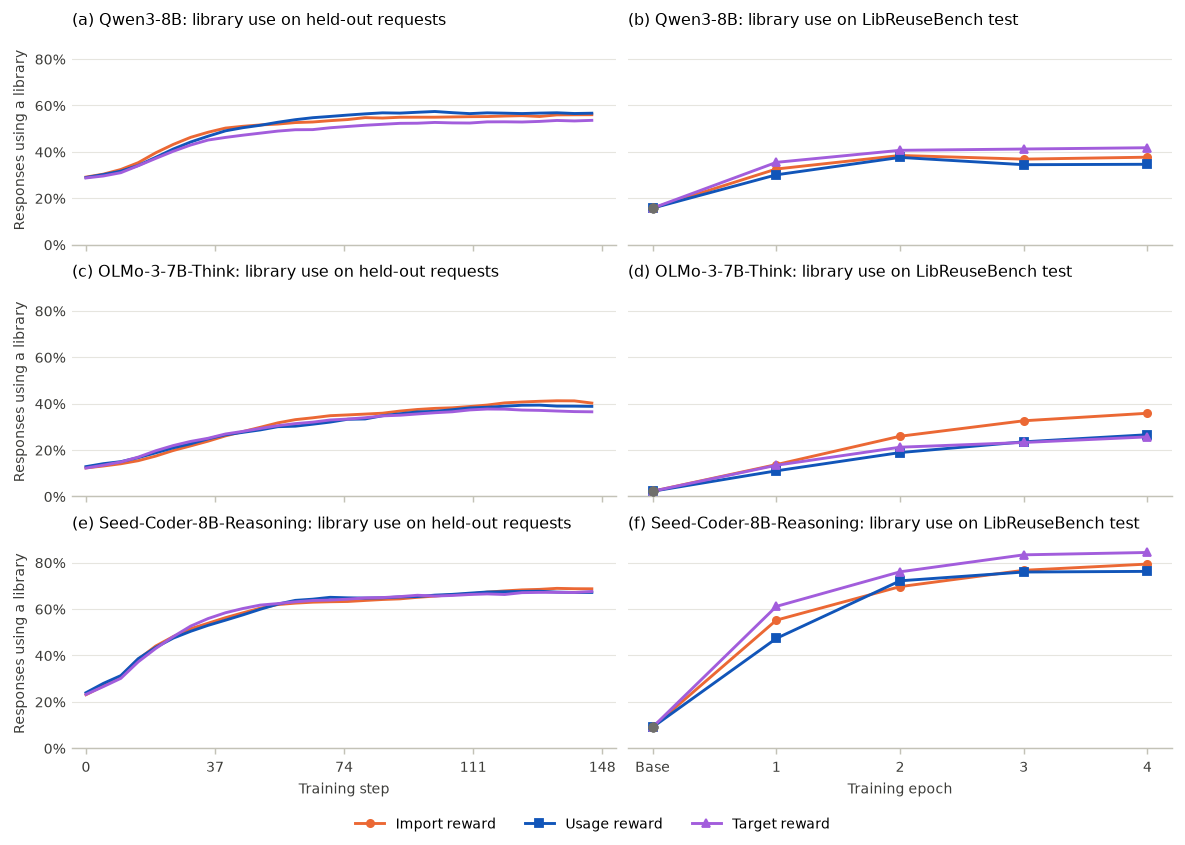

In [5]:
# the curves over training steps are smoothed over this many steps
SMOOTHING_STEPS = 25


def smooth(
    line: pd.Series,
) -> pd.Series:
    """
    Smooth a curve logged during training with a centred rolling mean over SMOOTHING_STEPS
    training steps, whatever the spacing of its points (the two ends average fewer).

    Returns the smoothed curve, on the same steps.
    """
    spacing = int(np.diff(line.index).min())
    return line.rolling(
        window=SMOOTHING_STEPS // spacing,
        center=True,
        min_periods=1,
    ).mean()


def plot_step_curves(
    ax: Axes,
    data: pd.DataFrame,
    column: str,
    linestyle: str = "-",
) -> None:
    """
    Draw one smoothed line per reward over the training steps, for one model, with a tick
    at the end of each epoch.
    """
    for reward in REWARDS:
        line = data[data["reward"] == reward].set_index("step")[column].sort_index()
        ax.plot(
            line.index,
            smooth(line),
            color=REWARD_COLOURS[reward],
            linestyle=linestyle,
            linewidth=1.6,
        )
    ax.set_xticks(EPOCH_END_STEPS)
    ax.set_xlim(-4, EPOCH_END_STEPS[-1] + 4)


def plot_epoch_curves(
    ax: Axes,
    data: pd.DataFrame,
) -> None:
    """
    Draw one line per reward over the epochs, for one model: library use at each epoch's
    checkpoint, with the base model's point (epoch 0) in grey.
    """
    for reward in REWARDS:
        line = data[data["reward"] == reward].set_index("epoch")["library use"]
        ax.plot(
            line.index,
            line.values,
            color=REWARD_COLOURS[reward],
            marker=REWARD_MARKERS[reward],
            markersize=4,
            linewidth=1.6,
            label=f"{reward.capitalize()} reward",
        )
        ax.plot(
            0,
            line[0],
            color=BASE_COLOUR,
            marker="o",
            markersize=4.5,
            linestyle="none",
            zorder=3,
        )
    ax.set_xticks(
        ALL_EPOCHS,
        labels=["Base", *(str(epoch) for epoch in EPOCHS)],
    )
    ax.set_xlim(-0.2, EPOCHS[-1] + 0.2)


def format_library_use_axis(
    ax: Axes,
) -> None:
    """
    Put library use on a panel's y axis: the top grid line is 80% and the axis stops at
    90%, to keep the figure short.
    """
    ax.set_ylim(0, 0.9)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set_ylabel("Responses using a library")


def make_figure_1(
    left_title: str,
) -> tuple[Figure, np.ndarray]:
    """
    Lay out figure 1 with one row per model. The right panels show library use on
    libreusebench test at each epoch; the left panels are titled here and drawn by the
    caller, with a curve over the training steps.

    Returns the figure and its grid of axes (one row per model, two columns).
    """
    fig, axes = plt.subplots(
        len(MODELS),
        2,
        figsize=(FIGURE_WIDTH, 6.4),
        layout="constrained",
        sharex="col",
        sharey="col",
    )
    letters = iter("abcdef")
    for row, (model, name) in enumerate(MODELS.items()):
        axes[row, 0].set_title(f"({next(letters)}) {name}: {left_title}")
        plot_epoch_curves(
            ax=axes[row, 1],
            data=transfer[transfer["model"] == model],
        )
        format_library_use_axis(ax=axes[row, 1])
        axes[row, 1].set_title(
            f"({next(letters)}) {name}: library use on LibReuseBench test",
        )
    axes[-1, 0].set_xlabel("Training step")
    axes[-1, 1].set_xlabel("Training epoch")
    return fig, axes


def reward_handles(
    axes: np.ndarray,
) -> list:
    """
    The legend entries for the rewards, taken from a libreusebench panel, whose lines carry
    the markers.

    Returns one legend handle per reward.
    """
    handles, _ = axes[0, 1].get_legend_handles_labels()
    return handles


# figure 1: library use on the held-out requests (left)
fig, axes = make_figure_1(left_title="library use on held-out requests")
for row, model in enumerate(MODELS):
    plot_step_curves(
        ax=axes[row, 0],
        data=held_out[held_out["model"] == model],
        column="library use",
    )
    format_library_use_axis(ax=axes[row, 0])
    # both columns share this y axis, so the right panels don't repeat it
    axes[row, 1].tick_params(labelleft=False)
    axes[row, 1].set_ylabel("")
handles = reward_handles(axes=axes)
fig.legend(
    handles=handles,
    loc="outside lower center",
    ncols=len(handles),
)
save_figure(fig=fig, name="figure_1_training_and_transfer")
plt.show()

## Figure 1 (reward version): the reward during training

As figure 1, but the left panels show each run's own reward instead of library use: solid for the training batches (logged every step) and dashed for the held-out test split (every 5 steps). Both lines are centred rolling means over 25 steps. The axis shows only 0.25 to 1.75, where the curves lie, so they can be told apart. The three rewards give credit for different things (importing any library, using any library, or using one of the task's target libraries; see `config/rewards.yaml`), but share one scale: 0.25 for the answer's format, 0.25 for passing a syntax check and 1.5 for the library credit, so 2 at most. The right panels are the same as in figure 1.

**Draft caption.** *Reward during training and transfer of library use.* Each run's own reward during four epochs (148 steps) of GRPO training, for Qwen3-8B (a), OLMo-3-7B-Think (c) and Seed-Coder-8B-Reasoning (e), on the training batches (solid) and on held-out feature requests from the training data's test split (dashed), as rolling means over 25 steps with a tick at each epoch's end. Every reward is out of 2. The training reward rises from 0.84-0.96 to 1.29-1.39 for Qwen3-8B, from 0.57-0.62 to 1.05-1.15 for OLMo-3-7B-Think and from 0.74-0.85 to 1.50-1.57 for Seed-Coder-8B-Reasoning, and the held-out reward follows it, ending 0.04-0.12 below. Library use on LibReuseBench test at each epoch's checkpoint (b, d, f) is as in Figure 1.

smoothed reward at the first and last step


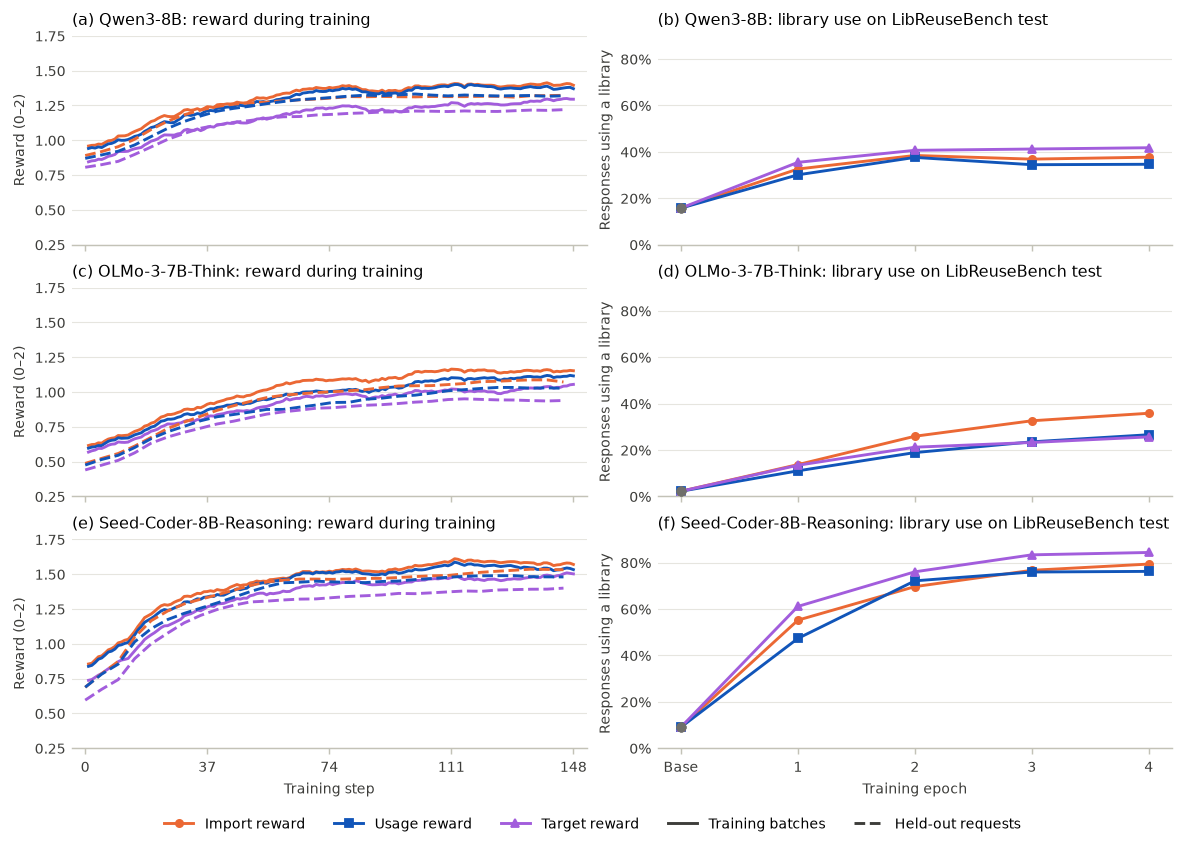

In [6]:
# each smoothed reward curve's first and last value, for the caption
print("smoothed reward at the first and last step")
display(
    pd.DataFrame(
        {
            (data_name, model, reward): smooth(
                data[(data["model"] == model) & (data["reward"] == reward)]
                .set_index("step")[column]
                .sort_index()
            )
            .iloc[[0, -1]]
            .to_numpy()
            for data_name, data, column in [
                ("training", training, "training reward"),
                ("held-out", held_out, "held-out reward"),
            ]
            for model in MODELS
            for reward in REWARDS
        },
        index=["start", "end"],
    ).T.style.format("{:.2f}")
)

# figure 1, reward version: the training and held-out reward (left)
fig, axes = make_figure_1(left_title="reward during training")
for row, model in enumerate(MODELS):
    plot_step_curves(
        ax=axes[row, 0],
        data=training[training["model"] == model],
        column="training reward",
    )
    plot_step_curves(
        ax=axes[row, 0],
        data=held_out[held_out["model"] == model],
        column="held-out reward",
        linestyle="--",
    )
    # every reward is out of 2, but the axis shows only where the curves lie
    assert all(
        0.25 <= value <= 1.75
        for line in axes[row, 0].get_lines()
        for value in line.get_ydata()
    ), "a reward curve is outside the axis"
    axes[row, 0].set_ylim(0.25, 1.75)
    axes[row, 0].set_yticks([0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75])
    axes[row, 0].set_ylabel("Reward (0–2)")
# the legend: each reward's colour, then the two line styles in the ink colour
handles = [
    *reward_handles(axes=axes),
    Line2D(
        [],
        [],
        color=INK,
        linewidth=1.6,
        label="Training batches",
    ),
    Line2D(
        [],
        [],
        color=INK,
        linewidth=1.6,
        linestyle="--",
        label="Held-out requests",
    ),
]
fig.legend(
    handles=handles,
    loc="outside lower center",
    ncols=len(handles),
)
save_figure(fig=fig, name="figure_1_reward_training_and_transfer")
plt.show()

## Table 1: main results

Each base model against its runs' final checkpoints (epoch 4), all with the plain prompt.

The caption says training increases library reuse and preserves correctness. The notebook checks both against the base model, with 95% paired-bootstrap intervals: library use on LibReuseBench test must rise (interval above zero), and no pass@1 may fall (no interval below zero). It prints every interval and stops if a check fails.

The table is saved as LaTeX. It needs the `booktabs` and `adjustbox` packages, and the paper's name macros (`\lure`, `\qwlil`, `\olmo`, `\seedcoder`, `\libreusebench`, `\humaneval`, `\livecodebench`).

**Caption.** *Effect of LURe training on Qwen3-8B, OLMo-3-7B-Think and Seed-Coder-8B-Reasoning.* Each run is reported at its final (fourth) epoch. Training substantially increases library reuse while preserving correctness on LibReuseBench, its control split, and general coding benchmarks. Lines saved measures the reduction in bespoke logical lines attributable to library use, while Tokens reports the mean number of generated tokens per task.

In [7]:
# the rows: for each model, the base model, then each reward's run at its final epoch
TABLE_ROWS = [(model, reward) for model in MODELS for reward in [None, *REWARDS]]
# the columns, in their groups: (group, heading, dataset, metric)
TABLE_COLUMNS = [
    ("LibReuseBench test", "Library use", "libreusebench_test", "library use"),
    (
        "LibReuseBench test",
        "High-value reuse",
        "libreusebench_test",
        "high-value reuse",
    ),
    ("LibReuseBench test", "pass@1", "libreusebench_test", "pass@1"),
    ("LibReuseBench test", "Lines saved", "libreusebench_test", "lines saved"),
    ("LibReuseBench test", "Tokens", "libreusebench_test", "tokens"),
    ("Control", "Library use", "libreusebench_control", "library use"),
    ("Control", "pass@1", "libreusebench_control", "pass@1"),
    ("General coding pass@1", "HumanEval+", "humaneval_plus", "pass@1"),
    ("General coding pass@1", "LiveCodeBench", "livecodebench", "pass@1"),
]


def row_label(
    model: str,
    reward: str | None,
) -> str:
    """
    Name a table row: the base model, or a run trained from it.

    Returns the row's label.
    """
    if reward is None:
        return MODELS[model]
    return f"+ {reward.capitalize()} reward"


# every value in the table, keyed by (model, reward, dataset, metric)
cells = {
    (model, reward, dataset, metric): task_values(
        model=model,
        reward=reward,
        epoch=FINAL_EPOCH,
        dataset=dataset,
        style="base",
        metric=metric,
    ).mean()
    for model, reward in TABLE_ROWS
    for _, _, dataset, metric in TABLE_COLUMNS
}

# check the caption's claims against each base model: library use on libreusebench test
# rises, and no pass@1 falls
for model, reward in TABLE_ROWS:
    if reward is None:
        continue
    for _, _, dataset, metric in TABLE_COLUMNS:
        is_reuse = (dataset, metric) == ("libreusebench_test", "library use")
        if not (is_reuse or metric == "pass@1"):
            continue
        difference, lower, upper = paired_bootstrap(
            trained=task_values(
                model=model,
                reward=reward,
                epoch=FINAL_EPOCH,
                dataset=dataset,
                style="base",
                metric=metric,
            ),
            base=task_values(
                model=model,
                reward=None,
                epoch=0,
                dataset=dataset,
                style="base",
                metric=metric,
            ),
        )
        print(
            f"{MODELS[model]} {reward}, {dataset} {metric}: {difference * 100:+.1f} "
            f"[{lower * 100:+.1f}, {upper * 100:+.1f}]"
        )
        if is_reuse:
            assert lower > 0, f"{model} {reward}: library use doesn't clearly rise"
        else:
            assert upper >= 0, f"{model} {reward}, {dataset}: pass@1 falls"


def format_value(
    value: float,
    metric: str,
) -> str:
    """
    Write a value as the table shows it.

    Returns lines to one decimal, a whole number of tokens, or a percentage to one
    decimal for a rate.
    """
    if metric == "lines saved":
        return f"{value:.1f}"
    if metric == "tokens":
        return f"{value:,.0f}"
    return f"{value:.1%}"


# the notebook's view of the table
display(
    pd.DataFrame(
        {
            (group, heading): [
                format_value(value=cells[model, reward, dataset, metric], metric=metric)
                for model, reward in TABLE_ROWS
            ]
            for group, heading, dataset, metric in TABLE_COLUMNS
        },
        index=pd.MultiIndex.from_tuples(
            [(MODELS[model], row_label(model, reward)) for model, reward in TABLE_ROWS]
        ),
    )
)

Qwen3-8B import, libreusebench_test library use: +21.9 [+17.5, +26.6]
Qwen3-8B import, libreusebench_test pass@1: +2.5 [-1.2, +6.0]
Qwen3-8B import, libreusebench_control pass@1: -0.7 [-4.3, +2.9]
Qwen3-8B import, humaneval_plus pass@1: -0.5 [-2.3, +1.3]
Qwen3-8B import, livecodebench pass@1: +0.9 [-3.0, +4.6]
Qwen3-8B usage, libreusebench_test library use: +18.9 [+14.8, +23.3]
Qwen3-8B usage, libreusebench_test pass@1: +1.0 [-2.4, +4.4]
Qwen3-8B usage, libreusebench_control pass@1: +2.9 [-1.7, +7.9]
Qwen3-8B usage, humaneval_plus pass@1: +0.2 [-1.2, +1.8]
Qwen3-8B usage, livecodebench pass@1: +4.6 [+0.5, +9.0]
Qwen3-8B target, libreusebench_test library use: +26.0 [+21.3, +31.0]
Qwen3-8B target, libreusebench_test pass@1: +2.9 [-0.7, +6.4]
Qwen3-8B target, libreusebench_control pass@1: +2.9 [-1.9, +8.1]
Qwen3-8B target, humaneval_plus pass@1: -0.4 [-1.7, +1.0]
Qwen3-8B target, livecodebench pass@1: +2.8 [-1.6, +7.1]
OLMo-3-7B-Think import, libreusebench_test library use: +33.6 [+28.6,

Seed-Coder-8B-Reasoning target, libreusebench_test pass@1: +26.9 [+21.2, +32.5]
Seed-Coder-8B-Reasoning target, libreusebench_control pass@1: +9.5 [+2.9, +16.4]
Seed-Coder-8B-Reasoning target, humaneval_plus pass@1: +0.2 [-2.6, +3.2]
Seed-Coder-8B-Reasoning target, livecodebench pass@1: +13.6 [+7.1, +20.0]


LibReuseBench test  \
                                                       Library use   
Qwen3-8B                Qwen3-8B                             15.7%   
                        + Import reward                      37.7%   
                        + Usage reward                       34.6%   
                        + Target reward                      41.8%   
OLMo-3-7B-Think         OLMo-3-7B-Think                       2.2%   
                        + Import reward                      35.8%   
                        + Usage reward                       26.6%   
                        + Target reward                      25.6%   
Seed-Coder-8B-Reasoning Seed-Coder-8B-Reasoning               9.1%   
                        + Import reward                      79.4%   
                        + Usage reward                       76.2%   
                        + Target reward                      84.4%   

                                                                         \
                                                High-value reuse pass@1   
Qwen3-8B                Qwen3-8B                           39.6%  75.5%   
                        + Import reward                    69.6%  78.0%   
                        + Usage reward                     67.3%  76.5%   
                        + Target reward                    72.7%  78.3%   
OLMo-3-7B-Think         OLMo-3-7B-Think                     6.5%  60.1%   
                        + Import reward                    63.5%  63.0%   
                        + Usage reward                     52.7%  66.0%   
                        + Target reward                    50.0%  64.8%   
Seed-Coder-8B-Reasoning Seed-Coder-8B-Reasoning            19.6%  42.4%   
                        + Import reward                    91.2%  70.1%   
                        + Usage reward                     91.5%  70.4%   
                        + Target reward                    94.6%  69.3%   

                                                                     \
                                                Lines saved  Tokens   
Qwen3-8B                Qwen3-8B                        0.7   9,158   
                        + Import reward                 3.9   7,434   
                        + Usage reward                  3.5   7,146   
                        + Target reward                 4.5   6,868   
OLMo-3-7B-Think         OLMo-3-7B-Think                 0.6  11,283   
                        + Import reward                 6.8   7,358   
                        + Usage reward                  5.4   7,375   
                        + Target reward                 5.6   7,576   
Seed-Coder-8B-Reasoning Seed-Coder-8B-Reasoning         1.2  12,781   
                        + Import reward                13.3   6,445   
                        + Usage reward                 11.2   6,427   
                        + Target reward                13.8   6,322   

                                                    Control         \
                                                Library use pass@1   
Qwen3-8B                Qwen3-8B                       0.0%  80.5%   
                        + Import reward                0.0%  79.8%   
                        + Usage reward                 0.7%  83.3%   
                        + Target reward                0.2%  83.3%   
OLMo-3-7B-Think         OLMo-3-7B-Think                0.0%  72.6%   
                        + Import reward                0.2%  78.6%   
                        + Usage reward                 0.0%  78.6%   
                        + Target reward                0.0%  76.4%   
Seed-Coder-8B-Reasoning Seed-Coder-8B-Reasoning        0.7%  71.9%   
                        + Import reward                9.3%  78.3%   
                        + Usage reward                 7.6%  80.0%   
                        + Target reward                7.1%  81.4%   

                                        

In [8]:
# the paper's macros for names, and pass@1 in italics
LATEX_NAMES = {
    "Qwen3-8B": r"\qwlil",
    "OLMo-3-7B-Think": r"\olmo",
    "Seed-Coder-8B-Reasoning": r"\seedcoder",
    "HumanEval+": r"\humaneval",
    "LiveCodeBench": r"\livecodebench",
    "pass@1": r"\textit{pass@1}",
}


def latex(
    text: str,
) -> str:
    """
    Write a table cell for LaTeX: escape the characters LaTeX treats specially, and use
    the paper's macros for names.

    Returns the LaTeX text.
    """
    text = text.replace("%", r"\%")
    for name, macro in LATEX_NAMES.items():
        text = text.replace(name, macro)
    return text


rows = []
for model, reward in TABLE_ROWS:
    # a rule between the models
    if reward is None and rows:
        rows.append(r"\midrule")
    values = [
        latex(format_value(value=cells[model, reward, dataset, metric], metric=metric))
        for _, _, dataset, metric in TABLE_COLUMNS
    ]
    rows.append(" & ".join([latex(row_label(model, reward)), *values]) + r" \\")

lines = [
    r"\begin{table*}[t]",
    r"\centering",
    "",
    r"\caption{",
    r"\textbf{Effect of \lure{} training on \qwlil{}, \olmo{} and \seedcoder{}.}",
    r"Each run is reported at its final (fourth) epoch.",
    r"Training substantially increases library reuse while preserving correctness on "
    r"\libreusebench{}, its control split, and general coding benchmarks.",
    r"\emph{Lines saved} measures the reduction in bespoke logical lines attributable to "
    r"library use, while \emph{Tokens} reports the mean number of generated tokens per task.",
    r"}",
    "",
    r"\label{tab:main-results}",
    "",
    r"    \begin{adjustbox}{width=\textwidth}",
    r"    \bgroup",
    r"    \def\arraystretch{1.4}",
    "",
    r"\begin{tabular}{lrrrrrrrrr}",
    r"\toprule",
    r" & \multicolumn{5}{c}{\libreusebench{} test} & \multicolumn{2}{c}{Control}"
    r" & \multicolumn{2}{c}{General coding \textit{pass@1}} \\",
    r"\cmidrule(lr){2-6} \cmidrule(lr){7-8} \cmidrule(lr){9-10}",
    " & ".join(["Model", *(latex(heading) for _, heading, _, _ in TABLE_COLUMNS)])
    + r" \\",
    r"\midrule",
    *rows,
    r"\bottomrule",
    r"\end{tabular}",
    r"\egroup",
    r"    \end{adjustbox}",
    r"\end{table*}",
]
table_file = OUTPUT_DIR / "table_1_main_results.tex"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
table_file.write_text("\n".join(lines) + "\n")
print(table_file.read_text())

\begin{table*}[t]
\centering

\caption{
\textbf{Effect of \lure{} training on \qwlil{}, \olmo{} and \seedcoder{}.}
Each run is reported at its final (fourth) epoch.
Training substantially increases library reuse while preserving correctness on \libreusebench{}, its control split, and general coding benchmarks.
\emph{Lines saved} measures the reduction in bespoke logical lines attributable to library use, while \emph{Tokens} reports the mean number of generated tokens per task.
}

\label{tab:main-results}

    \begin{adjustbox}{width=\textwidth}
    \bgroup
    \def\arraystretch{1.4}

\begin{tabular}{lrrrrrrrrr}
\toprule
 & \multicolumn{5}{c}{\libreusebench{} test} & \multicolumn{2}{c}{Control} & \multicolumn{2}{c}{General coding \textit{pass@1}} \\
\cmidrule(lr){2-6} \cmidrule(lr){7-8} \cmidrule(lr){9-10}
Model & Library use & High-value reuse & \textit{pass@1} & Lines saved & Tokens & Library use & \textit{pass@1} & \humaneval & \livecodebench \\
\midrule
\qwlil & 15.7\% & 39.6\% & 75

## Figure 2: prompting and training are complementary

LibReuseBench test, for each base model and each run's final checkpoint (epoch 4), with the plain prompt and with the suffix *"Use an external library when appropriate."*. Each group has six bars: Qwen3-8B, OLMo-3-7B-Think, then Seed-Coder-8B-Reasoning, each with the plain prompt then the suffix. Colour shows the model here, not the reward, and the bar's style shows the prompt: diagonal lines for the plain prompt, solid with the suffix.

**Draft caption.** *Training and prompt engineering are complementary.* Library use and code saved on LibReuseBench test for each base model and each run's final checkpoint (epoch 4), evaluated with the standard task prompt or with the suffix ``Use an external library when appropriate.'' Prompting alone substantially increases reuse, while applying the same instruction after LURe training increases it further, for every model. With the suffix, the best checkpoints reach 75.2% library use and save 8.5 logical lines per answer (Qwen3-8B, target reward), 69.2% and 11.1 lines (OLMo-3-7B-Think, import reward), and 95.6% and 17.0 lines (Seed-Coder-8B-Reasoning, target reward). Lines saved: how many logical lines shorter a library-using answer is than its base model's average hand-written answer to the same task (0 for an answer without a library). Error bars show ±1 standard error over tasks.

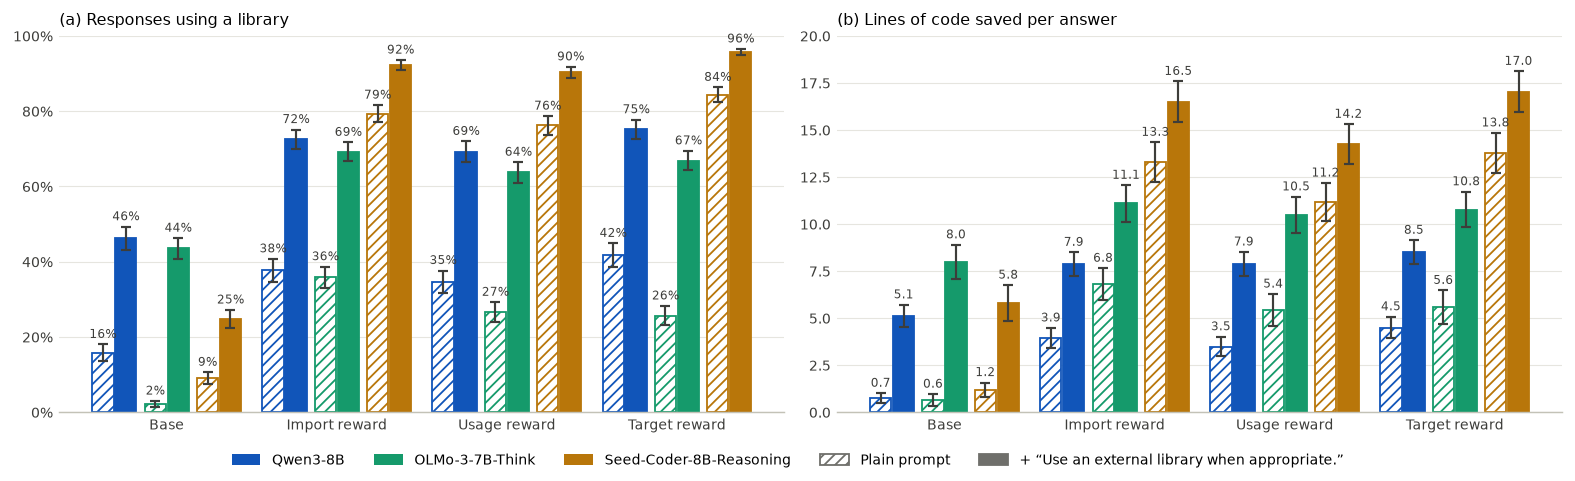

In [9]:
# the groups of bars: the base model, then each reward's run at its final epoch
FIGURE_2_GROUPS = {
    "Base": None,
    **{f"{reward.capitalize()} reward": reward for reward in REWARDS},
}
# each group's six bars, in order: each model with the plain prompt, then the suffix
FIGURE_2_BARS = [(model, style) for model in MODELS for style in PROMPT_STYLES]
# where each bar sits in its group: a small gap between a model's two bars, and a
# wider one between the models
BAR_WIDTH = 0.125
BAR_OFFSETS = [-0.375, -0.24, -0.0675, 0.0675, 0.24, 0.375]

bar_rows = []
for model in MODELS:
    for group, reward in FIGURE_2_GROUPS.items():
        for style in PROMPT_STYLES:
            for metric in ["library use", "lines saved"]:
                mean, error = mean_and_error(
                    task_values(
                        model=model,
                        reward=reward,
                        epoch=FINAL_EPOCH,
                        dataset="libreusebench_test",
                        style=style,
                        metric=metric,
                    )
                )
                bar_rows.append(
                    {
                        "model": model,
                        "group": group,
                        "style": style,
                        "metric": metric,
                        "value": mean,
                        "standard_error": error,
                    }
                )
bars = pd.DataFrame(bar_rows)

# the table view of the figure
display(
    bars.pivot_table(
        index=["model", "group", "style"],
        columns="metric",
        values=["value", "standard_error"],
        sort=False,
    ).style.format("{:.3f}")
)


def plot_prompt_bars(
    ax: Axes,
    metric: str,
    title: str,
) -> None:
    """
    Draw one panel of figure 2: six bars per group, each model with the plain prompt
    (diagonal lines) and then the suffix (solid), in the model's colour, each with its
    standard error and its value above it.
    """
    is_rate = metric == "library use"
    positions = np.arange(len(FIGURE_2_GROUPS))
    for offset, (model, style) in zip(BAR_OFFSETS, FIGURE_2_BARS):
        group = (
            bars[
                (bars["model"] == model)
                & (bars["metric"] == metric)
                & (bars["style"] == style)
            ]
            .set_index("group")
            .reindex(list(FIGURE_2_GROUPS))
        )
        x = positions + offset
        ax.bar(
            x,
            group["value"],
            width=BAR_WIDTH,
            # diagonal lines for the plain prompt, solid for the suffix
            color="white" if style == "base" else MODEL_COLOURS[model],
            edgecolor=MODEL_COLOURS[model],
            hatch=PLAIN_HATCH if style == "base" else None,
            linewidth=1,
        )
        ax.errorbar(
            x,
            group["value"],
            yerr=group["standard_error"],
            fmt="none",
            ecolor=INK,
            elinewidth=1.2,
            capsize=2.5,
            capthick=1.2,
        )
        for bar_x, value, error in zip(x, group["value"], group["standard_error"]):
            ax.annotate(
                f"{value:.0%}" if is_rate else f"{value:.1f}",
                xy=(bar_x, value + error),
                xytext=(0, 2),
                textcoords="offset points",
                ha="center",
                va="bottom",
                color=INK,
                fontsize=6.5,
            )
    ax.set_title(title)
    ax.set_xticks(positions, labels=list(FIGURE_2_GROUPS))
    ax.tick_params(axis="x", length=0)
    if is_rate:
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    else:
        # from 0 to 10 lines, or the next whole line if a bar and its label need more
        ax.set_ylim(0, max(10, math.ceil(ax.get_ylim()[1])))


fig, axes = plt.subplots(
    1,
    2,
    # wider than the other figures, so the labels over the 24 bars per panel stay readable
    figsize=(12, 3.6),
    layout="constrained",
)
plot_prompt_bars(
    ax=axes[0],
    metric="library use",
    title="(a) Responses using a library",
)
plot_prompt_bars(
    ax=axes[1],
    metric="lines saved",
    title="(b) Lines of code saved per answer",
)
# the legend: each model's colour, then the two bar styles in grey
handles = [
    *(
        Patch(
            facecolor=MODEL_COLOURS[model],
            label=name,
        )
        for model, name in MODELS.items()
    ),
    *(
        Patch(
            facecolor="white" if style == "base" else BASE_COLOUR,
            edgecolor=BASE_COLOUR,
            hatch=PLAIN_HATCH if style == "base" else None,
            linewidth=1,
            label=PROMPT_LABELS[style],
        )
        for style in PROMPT_STYLES
    ),
]
fig.legend(
    handles=handles,
    loc="outside lower center",
    ncols=len(handles),
)
save_figure(fig=fig, name="figure_2_prompting_and_training")
plt.show()